# 02 · How small can the panel get?
All numbers come from 5×5 repeated, patient-grouped CV, with gene selection redone inside every training fold.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from genepanel.cli import load_config, load_datasets
cfg = load_config('config/default.yaml')
TAB = f"{cfg['results_dir']}/tables"; FIG = f"{cfg['results_dir']}/figures"
pd.set_option('display.precision', 4)

In [2]:
summary = pd.read_csv(f'{TAB}/summary.csv')
ret = pd.read_csv(f'{TAB}/retention.csv')
vsr = pd.read_csv(f'{TAB}/vs_random.csv')

## AUC vs panel size
Dashed line: all genes. Gray band: 5–95% range of random gene panels of the same size (logistic regression).

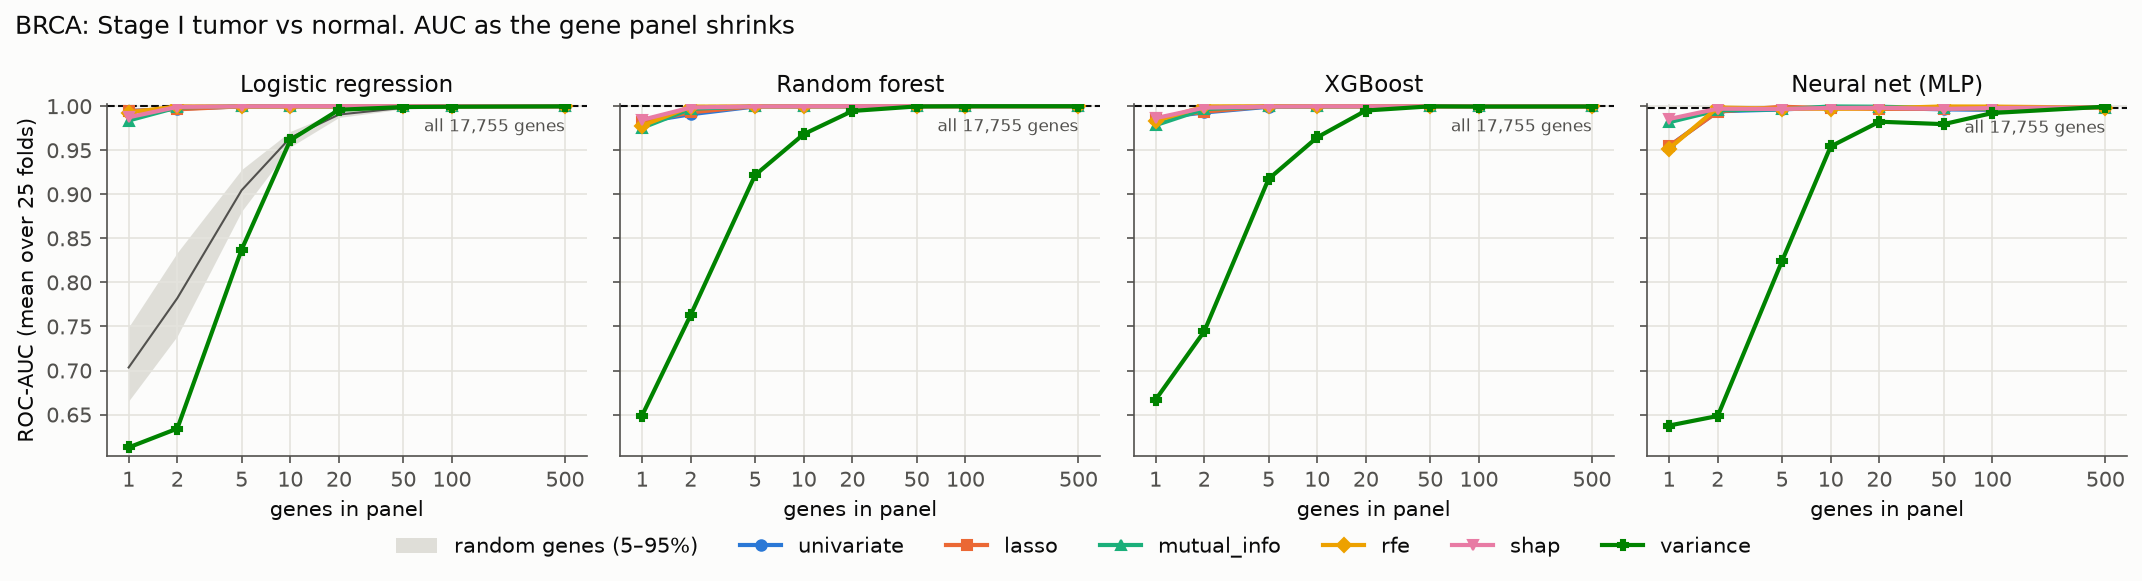

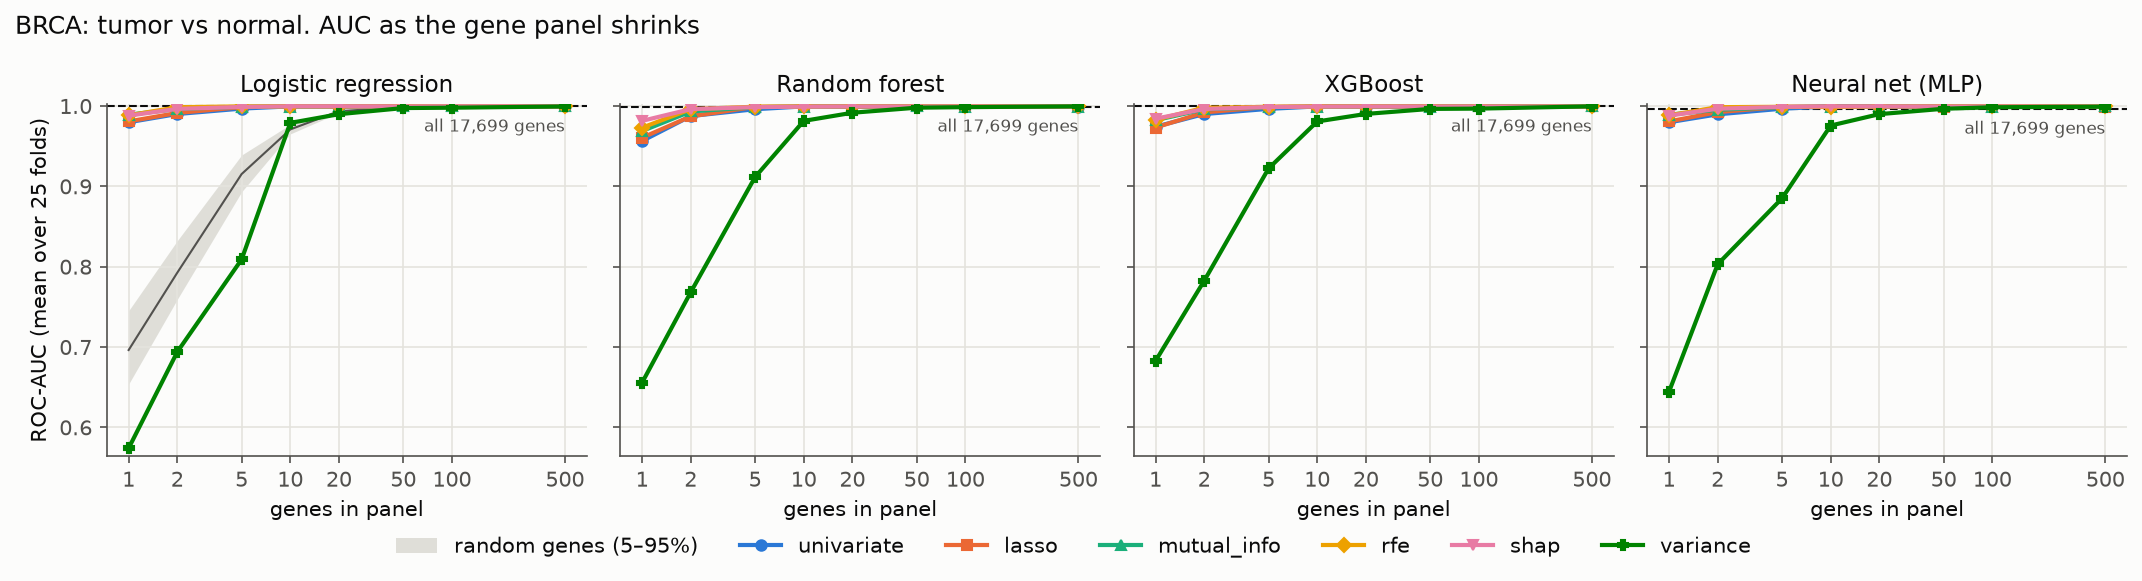

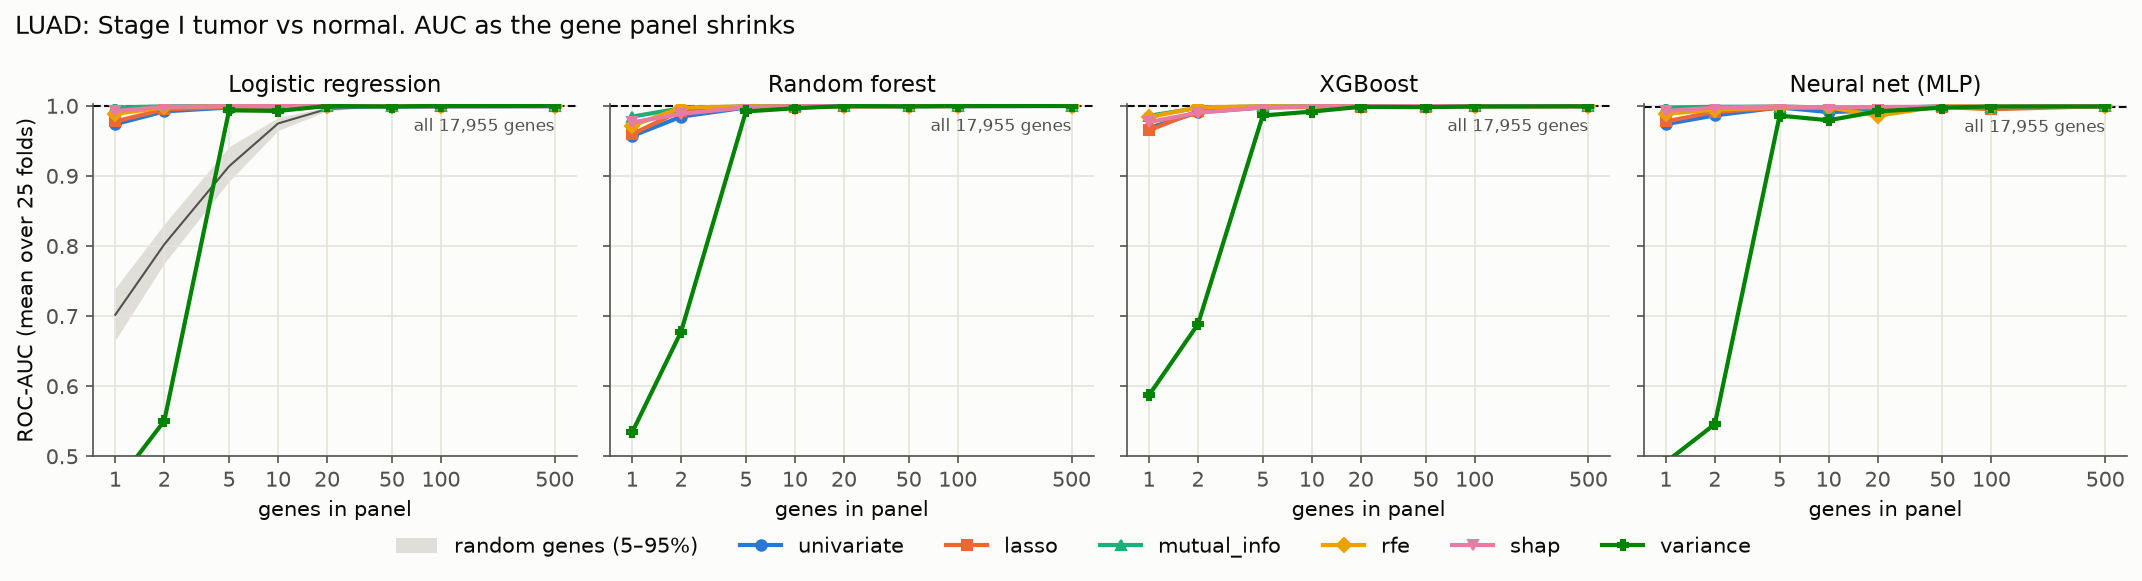

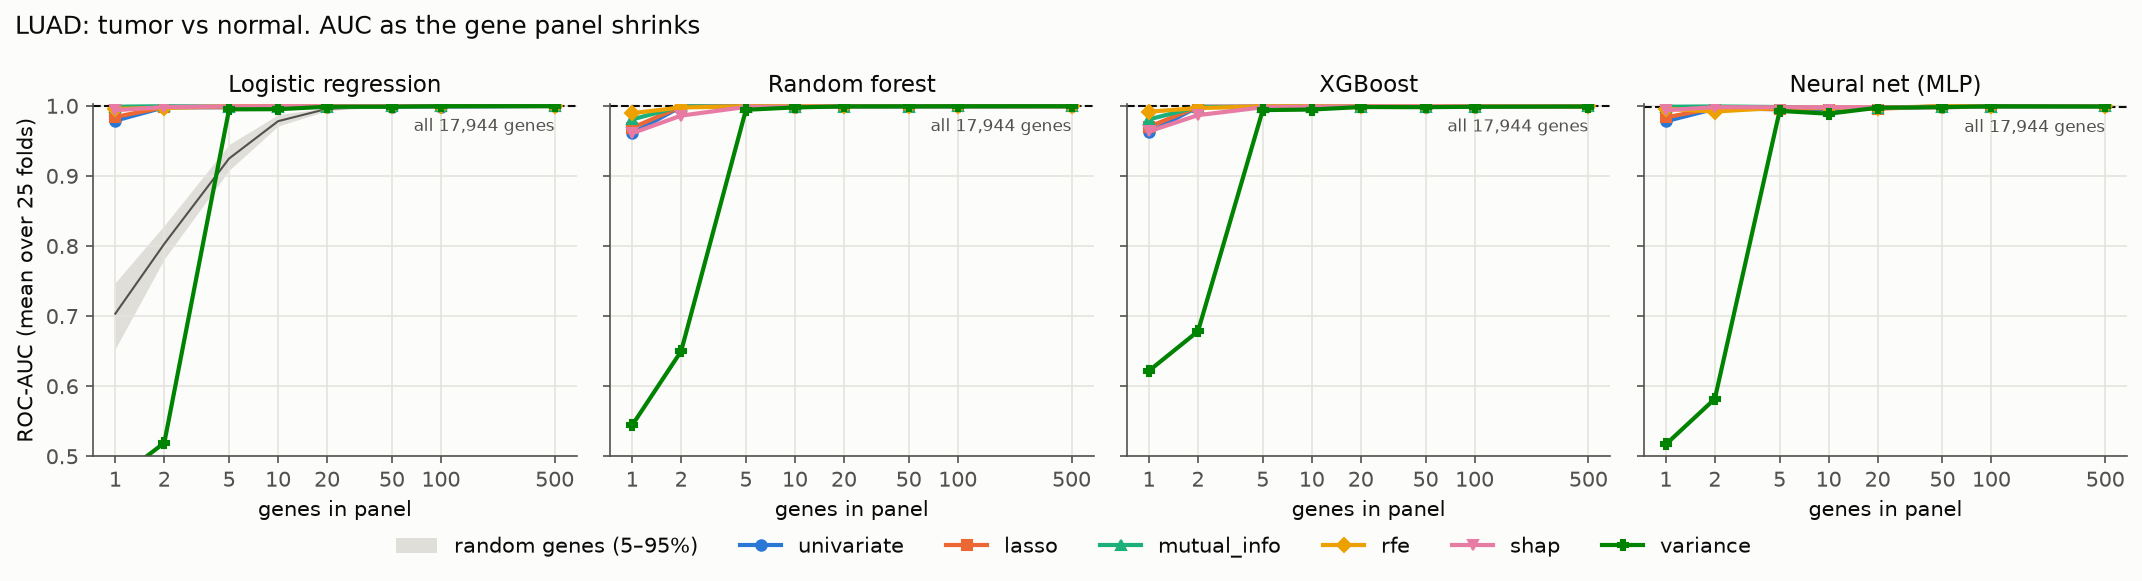

In [3]:
import glob
for f in sorted(glob.glob(f'{FIG}/auc_vs_k_*.png')):
    display(Image(f))

## The same curves as error (1 − AUC, log scale)
Near the ceiling, AUC plots hide the differences; this view shows them.

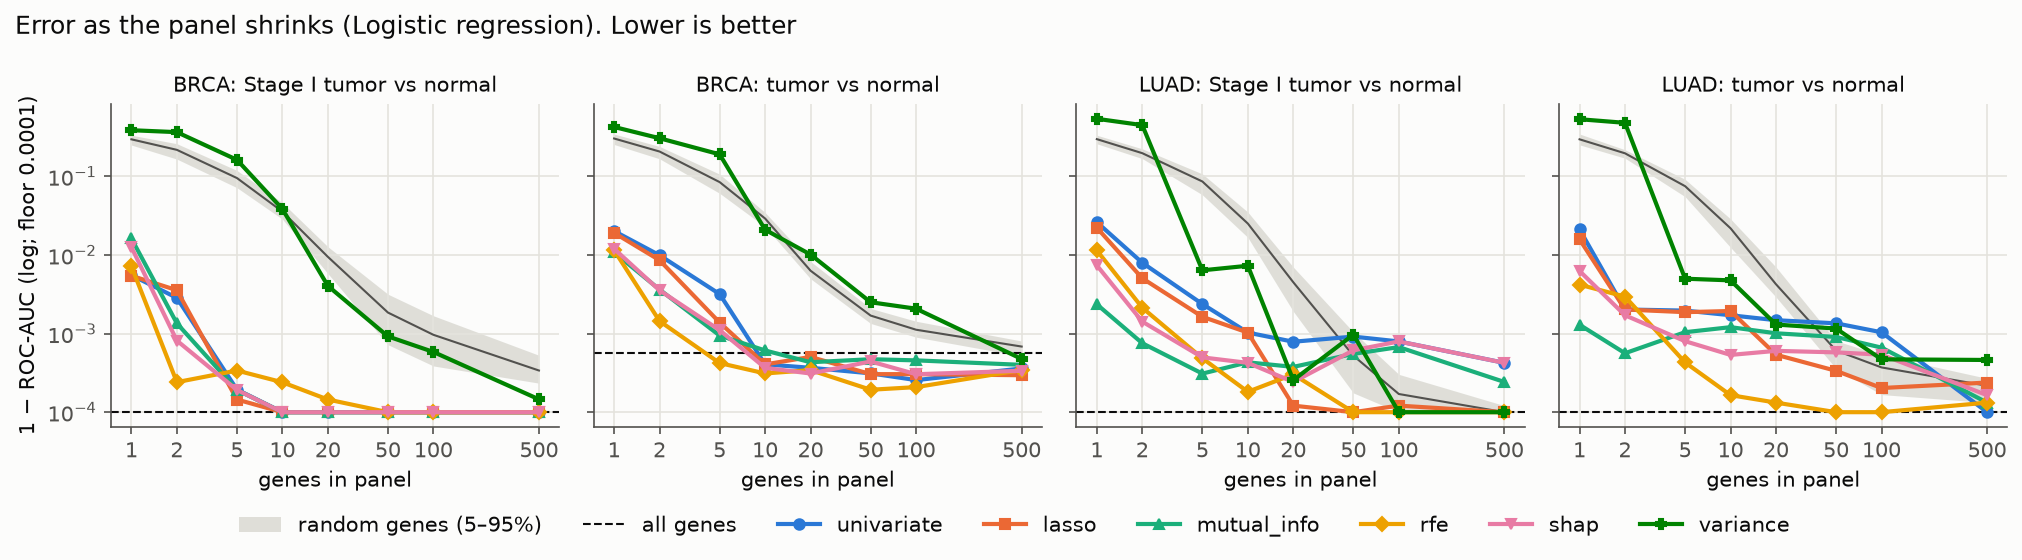

In [4]:
display(Image(f'{FIG}/error_vs_k_logreg.png'))

## Smallest panel that retains performance
Non-inferiority: the lower 95% bound of the paired fold-wise AUC difference (panel − all genes) must stay above −0.01.

In [5]:
ret.pivot_table(index=['cancer', 'task', 'selector'], columns='model', values='smallest_retained_k')

model                                logreg    mlp    rf   xgb
cancer task             selector                              
BRCA   stage1_vs_normal lasso           1.0    2.0   5.0   2.0
                        mutual_info     2.0    2.0   2.0   2.0
                        rfe             1.0    2.0   2.0   2.0
                        shap            2.0    2.0   2.0   2.0
                        univariate      1.0    2.0   5.0   5.0
                        variance       20.0  500.0  20.0  20.0
       tumor_vs_normal  lasso           5.0    2.0   5.0   2.0
                        mutual_info     2.0    2.0   2.0   2.0
                        rfe             2.0    2.0   2.0   2.0
                        shap            2.0    2.0   2.0   2.0
                        univariate      5.0    5.0   5.0   5.0
                        variance       50.0   50.0  20.0  50.0
LUAD   stage1_vs_normal lasso           2.0    5.0   5.0   5.0
                        mutual_info     1.0    1.0   2.0   2.0
                        rfe             2.0    2.0   2.0   2.0
                        shap            2.0    1.0   5.0   5.0
                        univariate      5.0    5.0   5.0   5.0
                        variance        5.0   50.0  10.0  20.0
       tumor_vs_normal  lasso           2.0    2.0   2.0   2.0
                        mutual_info     1.0    1.0   2.0   2.0
                        rfe             1.0    1.0   2.0   2.0
                        shap            1.0    1.0   5.0   5.0
                        univariate      2.0    2.0   2.0   2.0
                        variance        5.0    5.0   5.0   5.0

## Do selected panels beat random genes?

In [6]:
(vsr[vsr.k.isin([1, 2, 5, 10])].pivot_table(index=['cancer', 'task', 'k'], columns='selector', values='auc')
   .join(vsr.groupby(['cancer', 'task', 'k']).random_auc_mean.first().rename('RANDOM')))

lasso  mutual_info     rfe    shap  univariate  \
cancer task             k                                                     
BRCA   stage1_vs_normal 1   0.9946       0.9837  0.9928  0.9874      0.9945   
                        2   0.9964       0.9986  0.9998  0.9992      0.9972   
                        5   0.9999       0.9998  0.9997  0.9998      0.9998   
                        10  1.0000       1.0000  0.9998  1.0000      1.0000   
       tumor_vs_normal  1   0.9809       0.9892  0.9885  0.9880      0.9798   
                        2   0.9914       0.9964  0.9986  0.9964      0.9901   
                        5   0.9986       0.9991  0.9996  0.9989      0.9968   
                        10  0.9996       0.9994  0.9997  0.9996      0.9996   
LUAD   stage1_vs_normal 1   0.9778       0.9976  0.9886  0.9926      0.9738   
                        2   0.9949       0.9992  0.9979  0.9986      0.9920   
                        5   0.9984       0.9997  0.9995  0.9995      0.9976   
                        10  0.9990       0.9996  0.9998  0.9996      0.9990   
       tumor_vs_normal  1   0.9842       0.9987  0.9958  0.9937      0.9788   
                        2   0.9980       0.9994  0.9970  0.9983      0.9980   
                        5   0.9981       0.9990  0.9996  0.9992      0.9980   
                        10  0.9981       0.9988  0.9998  0.9995      0.9983   

                            variance  RANDOM  
cancer task             k                     
BRCA   stage1_vs_normal 1     0.6127  0.7035  
                        2     0.6341  0.7821  
                        5     0.8373  0.9046  
                        10    0.9615  0.9643  
       tumor_vs_normal  1     0.5740  0.6963  
                        2     0.6940  0.7926  
                        5     0.8091  0.9154  
                        10    0.9790  0.9709  
LUAD   stage1_vs_normal 1     0.4589  0.7019  
                        2     0.5505  0.8024  
                        5     0.9936  0.9138  
                        10    0.9927  0.9749  
       tumor_vs_normal  1     0.4656  0.7035  
                        2     0.5192  0.8031  
                        5     0.9950  0.9248  
                        10    0.9952  0.9781

## Beyond AUC: sensitivity at 95% specificity
The clinically relevant operating point for screening.

In [7]:
summary[summary.k.isin([1, 5, 10, 50]) & (summary.model == 'logreg') & (summary.selector != 'random')]\
  .pivot_table(index=['cancer', 'task', 'k'], columns='selector', values='sens_at_95spec_mean')

selector                     lasso  mutual_info     rfe    shap  univariate  \
cancer task             k                                                     
BRCA   stage1_vs_normal 1   0.9758       0.9627  0.9659  0.9747      0.9747   
                        5   1.0000       0.9989  0.9978  0.9989      1.0000   
                        10  1.0000       1.0000  0.9989  1.0000      1.0000   
                        50  1.0000       1.0000  1.0000  1.0000      1.0000   
       tumor_vs_normal  1   0.9265       0.9661  0.9635  0.9730      0.9222   
                        5   0.9944       0.9956  0.9976  0.9956      0.9852   
                        10  0.9976       0.9969  0.9984  0.9978      0.9982   
                        50  0.9982       0.9967  0.9985  0.9975      0.9980   
LUAD   stage1_vs_normal 1   0.8679       0.9847  0.9432  0.9738      0.8349   
                        5   0.9825       0.9964  0.9949  0.9942      0.9745   
                        10  0.9891       0.9964  0.9978  0.9971      0.9891   
                        50  0.9993       0.9949  1.0000  0.9949      0.9934   
       tumor_vs_normal  1   0.8971       0.9899  0.9810  0.9662      0.8344   
                        5   0.9841       0.9930  0.9957  0.9957      0.9852   
                        10  0.9864       0.9922  0.9981  0.9961      0.9856   
                        50  0.9965       0.9934  0.9988  0.9953      0.9887   

selector                    variance  
cancer task             k             
BRCA   stage1_vs_normal 1     0.3438  
                        5     0.3232  
                        10    0.8429  
                        50    0.9956  
       tumor_vs_normal  1     0.2992  
                        5     0.4760  
                        10    0.9067  
                        50    0.9874  
LUAD   stage1_vs_normal 1     0.0422  
                        5     0.9774  
                        10    0.9781  
                        50    0.9949  
       tumor_vs_normal  1     0.0490  
                        5     0.9802  
                        10    0.9864  
                        50    0.9953

## Selector × model at k = 10

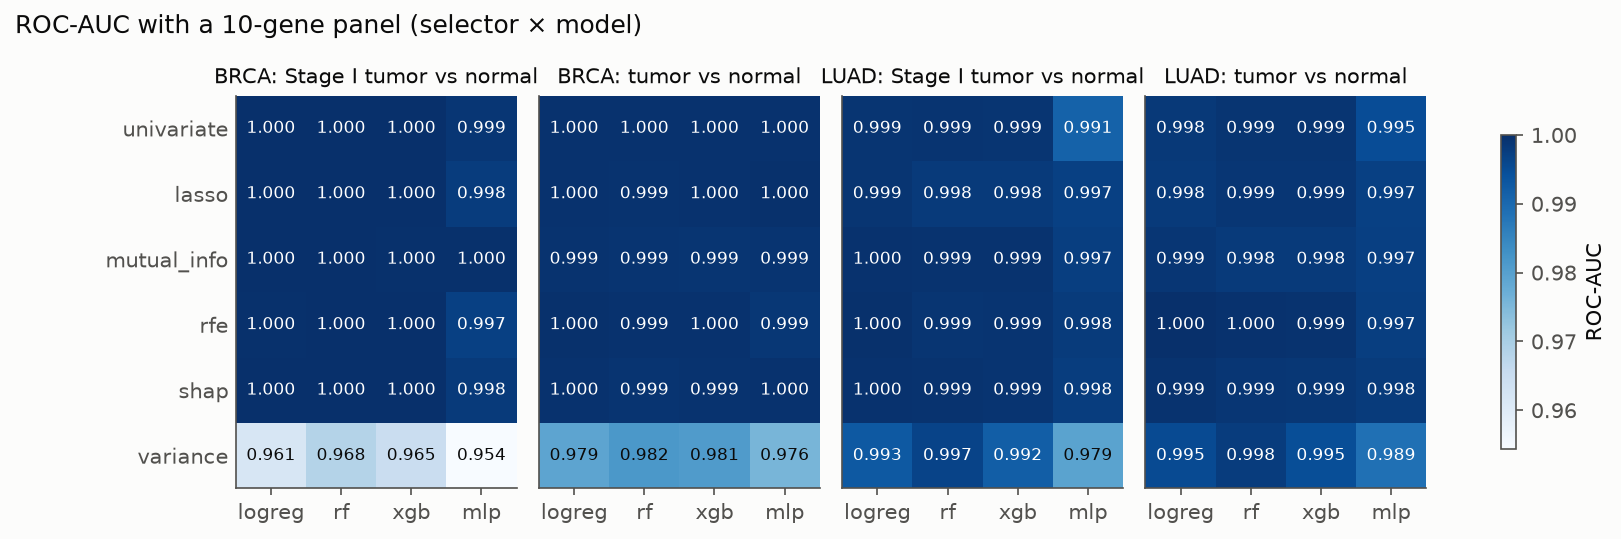

In [8]:
display(Image(f'{FIG}/heatmap_k10.png'))

## …and at k = 1

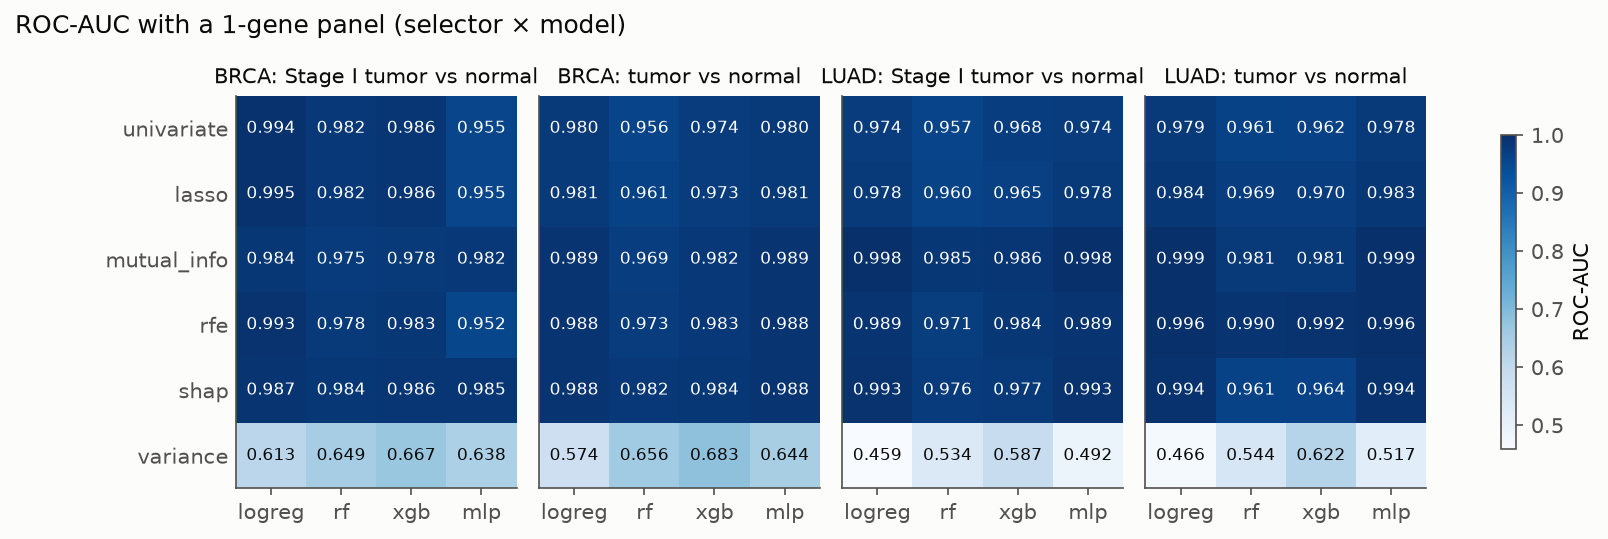

In [9]:
display(Image(f'{FIG}/heatmap_k1.png'))

## Stability

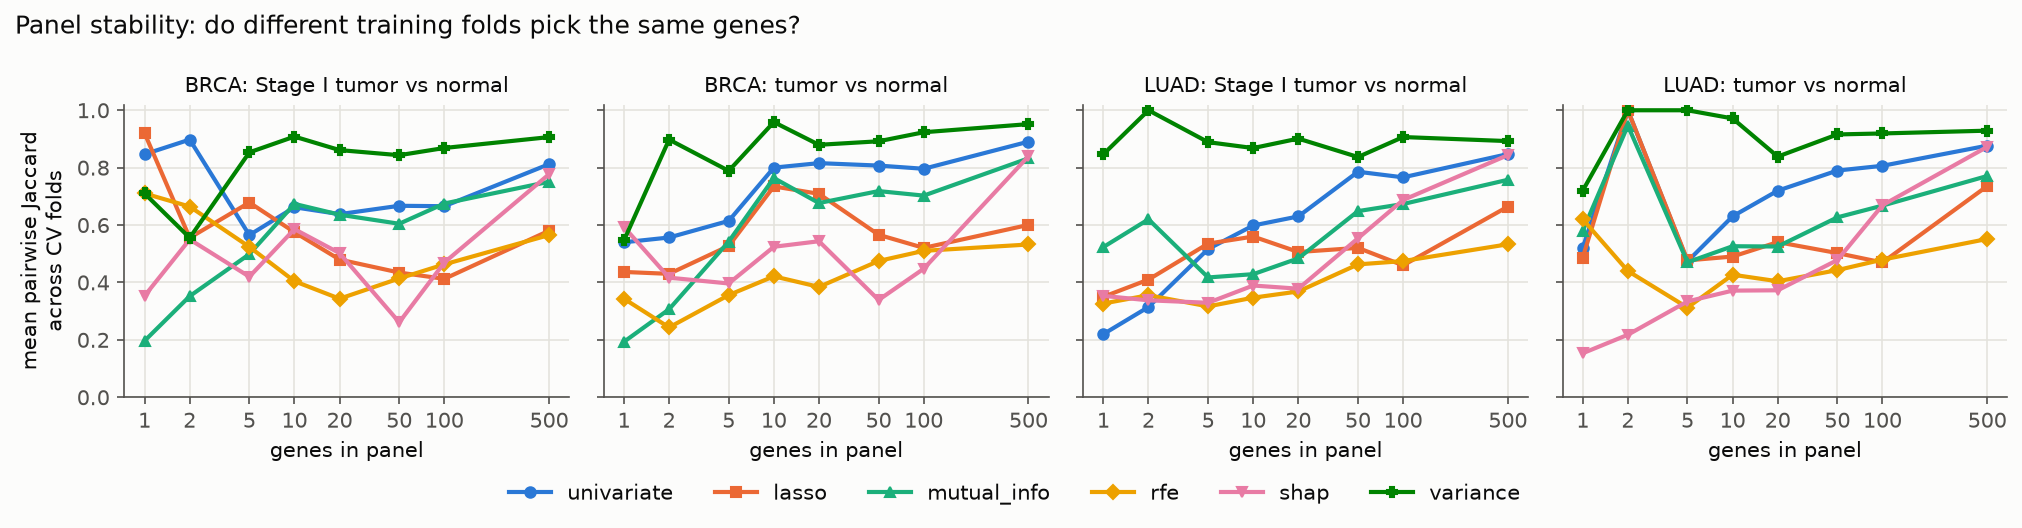

In [10]:
display(Image(f'{FIG}/stability.png'))

## Cross-cancer transfer of the consensus 10-gene panel

In [11]:
pd.read_csv(f'{TAB}/transfer.csv')

,task,panel_from,evaluated_on,mode,n_genes,auc,pr_auc,bal_acc,sens_at_95spec
0,tumor_vs_normal,BRCA,BRCA,within_cv_in_sample,10,0.9997,1.0000,0.9949,0.9982
1,tumor_vs_normal,BRCA,LUAD,direct,9,0.9972,0.9997,0.9757,0.9786
2,tumor_vs_normal,BRCA,LUAD,within_cv,9,0.9979,0.9998,0.9827,0.9872
3,tumor_vs_normal,LUAD,BRCA,direct,9,0.9636,0.9957,0.5263,0.7603
4,tumor_vs_normal,LUAD,BRCA,within_cv,9,0.9954,0.9995,0.9600,0.9785
5,tumor_vs_normal,LUAD,LUAD,within_cv_in_sample,10,0.9994,0.9999,0.9900,0.9942
6,stage1_vs_normal,BRCA,BRCA,within_cv_in_sample,10,1.0000,1.0000,0.9945,1.0000
7,stage1_vs_normal,BRCA,LUAD,direct,10,0.9979,0.9996,0.9872,0.9891
8,stage1_vs_normal,BRCA,LUAD,within_cv,10,0.9980,0.9996,0.9836,0.9861
9,stage1_vs_normal,LUAD,BRCA,direct,9,0.9636,0.9744,0.5439,0.7912
